<img src="recursos/logo_UTN.svg" align="right" width="150" /> 

#### Teoría de Circuitos II

# Trabajo Práctico de Laboratorio 2

Docentes: *LLAMEDO SORIA, Mariano* y *MOHAROS, David*

Integrantes: *MARCHESI, Matías Sebastián*, *PARISEK, Alan Nicolas* y *RODRIGUEZ SILVOSA, Martín*

Grupo 4

Autor: *MARCHESI, Matías Sebastián*

## Introducción

En este trabajo práctico se analiza el funcionamiento de un sistema de procesamiento digital de señales implementado sobre un microcontrolador STM32. El sistema permite adquirir una señal analógica mediante un conversor analógico-digital (ADC), realizar su procesamiento digital y posteriormente reconstruir la señal mediante un conversor digital-analógico (DAC).

El trabajo se realiza sobre un filtro de tipo **Notch**, cuya frecuencia central especificada es $50\,Hz$ y cuyo ancho de banda a $3\,dB$ es de $1\,Hz$.

Para verificar el correcto funcionamiento del sistema se analizan tres modos de operación. En primer lugar, se utiliza el modo **Talk-Through**, con el objetivo de comprobar el funcionamiento de la cadena de adquisición y reconstrucción. Luego se evalúa el comportamiento de un filtro digital **FIR** y, finalmente, el de un filtro digital **IIR**.

A partir de las simulaciones y mediciones experimentales se busca caracterizar el comportamiento de los distintos modos de funcionamiento y comparar los resultados obtenidos con las especificaciones de diseño.

## Descripción del sistema y especificaciones

El sistema utilizado para el procesamiento de la señal está compuesto por una etapa de adquisición analógica, un procesamiento digital realizado mediante el microcontrolador STM32 y una etapa de reconstrucción de la señal a la salida.

El sistema completo puede representarse de la siguiente manera:

<div style="text-align: center;">
  <img src="recursos/conexion.png" width="550">
</div>


### Filtros analógicos

Tanto el filtro RC ubicado antes del ADC como el filtro RC ubicado luego del DAC están implementados con una resistencia de $6.8\,k\Omega$ y un capacitor de $100\,nF$.

La forma de conexión es la siguiente: 
<div style="text-align: center;">
  <img src="recursos/antialias.png" width="550">
</div>

La frecuencia característica de ambos filtros se obtiene mediante:

$$f_0 = \frac{1}{2\pi RC}$$

Reemplazando los valores utilizados:

$$f_0 = \frac{1}{2\pi(6.8\,k\Omega)(100\,nF)} \approx 234\,Hz$$

Por lo tanto, ambos filtros RC presentan una frecuencia característica de aproximadamente $234\,Hz$.

### Modos de funcionamiento

Para comprobar el correcto funcionamiento del sistema se analizaron tres modos de funcionamiento:

1. **Talk-Through:** permite verificar el funcionamiento general del sistema. En este modo la señal adquirida se vuelve a enviar a la salida sin aplicar un filtrado digital específico, por lo que se espera obtener una señal de salida equivalente a la señal de entrada, considerando el retardo introducido por el procesamiento.

2. **Filtro FIR:** se utiliza un filtro digital FIR diseñado para obtener un Notch en $50\,Hz$.

3. **Filtro IIR:** se utiliza un filtro digital IIR, también diseñado para obtener un Notch en $50\,Hz$.

### Especificaciones del filtro digital

Para el filtro Notch se establece como frecuencia central:

$$f_{notch} = 50\,Hz$$

y como ancho de banda a $3\,dB$:

$$BW_{3dB} = 1\,Hz$$

La consigna define para este filtro una frecuencia de notch de $50\,Hz$ y un ancho de banda de $1\,Hz$.

En el diseño realizado mediante Python se utiliza una frecuencia de muestreo de:

$$f_s = 1000\,Hz$$

La plantilla utilizada para el diseño del filtro establece los siguientes límites:

- $f_{p1} = 49\,Hz$
- $f_{s1} = 49.5\,Hz$
- $f_{s2} = 50.5\,Hz$
- $f_{p2} = 51\,Hz$
- $\alpha_{max} = 1\,dB$
- $\alpha_{min} = 60\,dB$

De esta manera, se busca obtener un filtro que atenúe fuertemente las componentes próximas a $50\,Hz$, manteniendo una respuesta prácticamente sin atenuación fuera de la banda de rechazo.

La plantilla de diseño se representa mediante la siguiente simulación:

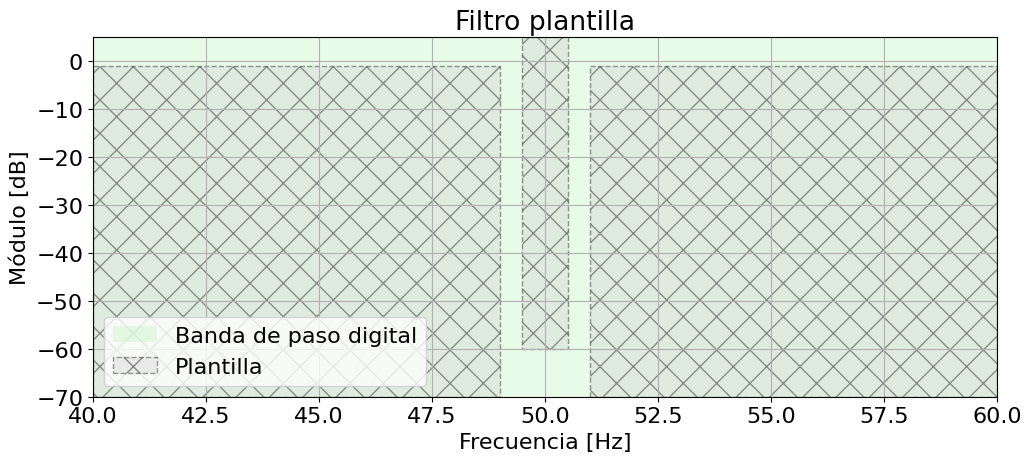

In [54]:
import warnings
warnings.filterwarnings('ignore')

import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import scipy.io as sio
from pytc2.sistemas_lineales import plot_plantilla

fig_sz_x = 14
fig_sz_y = 7
fig_font_size = 16

plt.rcParams.update({'font.size':fig_font_size})

fs = 1000 # Hz
nyq_frec = fs / 2

# Plantilla

ripple = 1 # dB
atenuacion = 60 # dB

ws1 = 49.5 #Hz
wp1 = 49 #Hz
wp2 = 51.0 #Hz
ws2 = 50.5 #Hz

plt.figure(1, figsize=(fig_sz_x/1.2, fig_sz_y/1.5))
plt.axis([40, 60, -70, 5 ]);

plot_plantilla(filter_type = 'bandstop', fpass = (wp1, wp2), fstop =  (ws1, ws2), ripple = ripple, attenuation = atenuacion, fs = fs)

plt.title('Filtro plantilla')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
_ = plt.legend()

## Diseño de filtros digitales

A partir de las especificaciones definidas para el filtro Notch se diseñaron dos filtros digitales, uno FIR y otro IIR. Para ambos casos se utilizaron las herramientas de procesamiento de señales disponibles en `scipy.signal`.

### Diseño del filtro FIR

El filtro FIR se diseñó utilizando la función `firwin2` de `scipy.signal`, definiendo la respuesta en frecuencia deseada a partir de la plantilla establecida para el filtro Notch.

Para el diseño se utilizaron $3001$ coeficientes. La cantidad de coeficientes determina la cantidad de términos utilizados para implementar el filtro y, en este caso, permite obtener una transición suficientemente abrupta alrededor de la frecuencia de rechazo de $50\,Hz$.

La respuesta deseada presenta una ganancia cercana a la unidad fuera de la zona de rechazo y una fuerte atenuación alrededor de $50\,Hz$, de acuerdo con las especificaciones del filtro.

Para el diseño se utilizó una ventana de Kaiser. Esta ventana permite ajustar el comportamiento del filtro y controlar el compromiso entre una transición más rápida alrededor de la frecuencia de rechazo y una respuesta más limpia. Su comportamiento se ajusta mediante el parámetro $\beta$, que en este caso se estableció en $\beta=5$.

In [55]:
cant_coeficientes = 3001

frecuencias = [
    0, 48.2, 49.2, 49.3, 49.4, 49.5,
    49.6, 49.7, 49.8, 49.9, 50.0, 50.1,
    50.2, 50.3, 50.4, 50.5, 50.6, 50.7,
    50.8, 50.9, 51.0, 51.1, 51.2, 52.2,
    nyq_frec
]

ganancia = [
    1, 1, 1,
    0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
    0, 0, 0, 0, 0,0,
    1, 1, 1
]

ventana = ('kaiser', 5)

num_win = sig.firwin2(
    cant_coeficientes,
    freq=frecuencias,
    gain=ganancia,
    window=ventana,
    fs=fs
)

### Diseño del filtro IIR

El filtro IIR se diseñó utilizando la función `iirdesign` de `scipy.signal`, a partir de la plantilla definida para el filtro Notch.

Para el diseño se utilizó una aproximación **Chebyshev**, con un $\alpha_{max}$ de $1\,dB$ y un $\alpha_{min}$ de $60\,dB$.

La frecuencia de rechazo se encuentra centrada en $50\,Hz$. Para definir la zona de transición se utilizaron las frecuencias $49\,Hz$ y $51\,Hz$ para la banda pasante, y $49.5\,Hz$ y $50.5\,Hz$ para la banda de rechazo.

La frecuencia de muestreo utilizada para el diseño es $f_s=1000\,Hz$.

A diferencia del filtro FIR, el filtro IIR permite obtener una respuesta similar utilizando una cantidad menor de coeficientes. El resultado del diseño se obtiene mediante secciones de segundo orden, que luego pueden utilizarse para implementar el filtro en el microcontrolador.

In [56]:
ripple_iterado = 1
atenuacion_iterado = 60

sos_iir = sig.iirdesign(
    wp=[wp1, wp2],
    ws=[ws1, ws2],
    gpass=ripple_iterado,
    gstop=atenuacion_iterado,
    output='sos',
    analog=False,
    ftype='cheby1',
    fs=fs
)

## Simulación

### Respuesta en frecuencia del filtro FIR

Una vez obtenidos los coeficientes del filtro FIR, se simuló su respuesta en frecuencia para analizar el comportamiento del filtro alrededor de la frecuencia de rechazo.

A continuación se presenta la respuesta en frecuencia obtenida mediante Python.

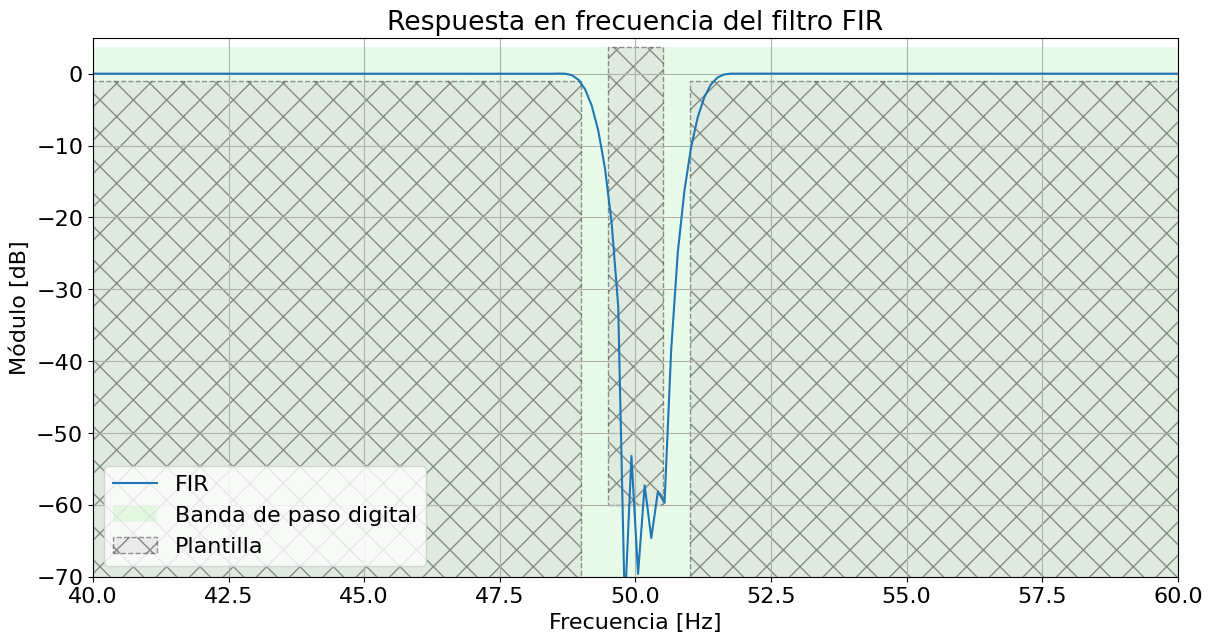

In [57]:
w, hh_win = sig.freqz(
    num_win,
    worN=4096,
    fs=fs
)

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    w,
    20 * np.log10(np.abs(hh_win) + 1e-12),
    label='FIR'
)

plot_plantilla(
    filter_type='bandstop',
    fpass=(wp1, wp2),
    fstop=(ws1, ws2),
    ripple=ripple,
    attenuation=atenuacion,
    fs=fs
)

plt.title('Respuesta en frecuencia del filtro FIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.xlim(40, 60)
plt.ylim(-70, 5)
plt.grid()
plt.legend()
plt.show()

La respuesta obtenida muestra una fuerte atenuación alrededor de la frecuencia de $50\,Hz$, mientras que fuera de la zona de rechazo la ganancia se mantiene próxima a $0\,dB$.

### Respuesta en frecuencia del filtro IIR

A partir de las secciones de segundo orden obtenidas durante el diseño del filtro IIR, se simuló su respuesta en frecuencia utilizando la misma frecuencia de muestreo, $f_s=1000\,Hz$.

La simulación permite observar el comportamiento del filtro alrededor de la frecuencia de notch de $50\,Hz$ y verificar la atenuación obtenida en la banda de rechazo.

A continuación se presenta la respuesta en frecuencia obtenida mediante Python.

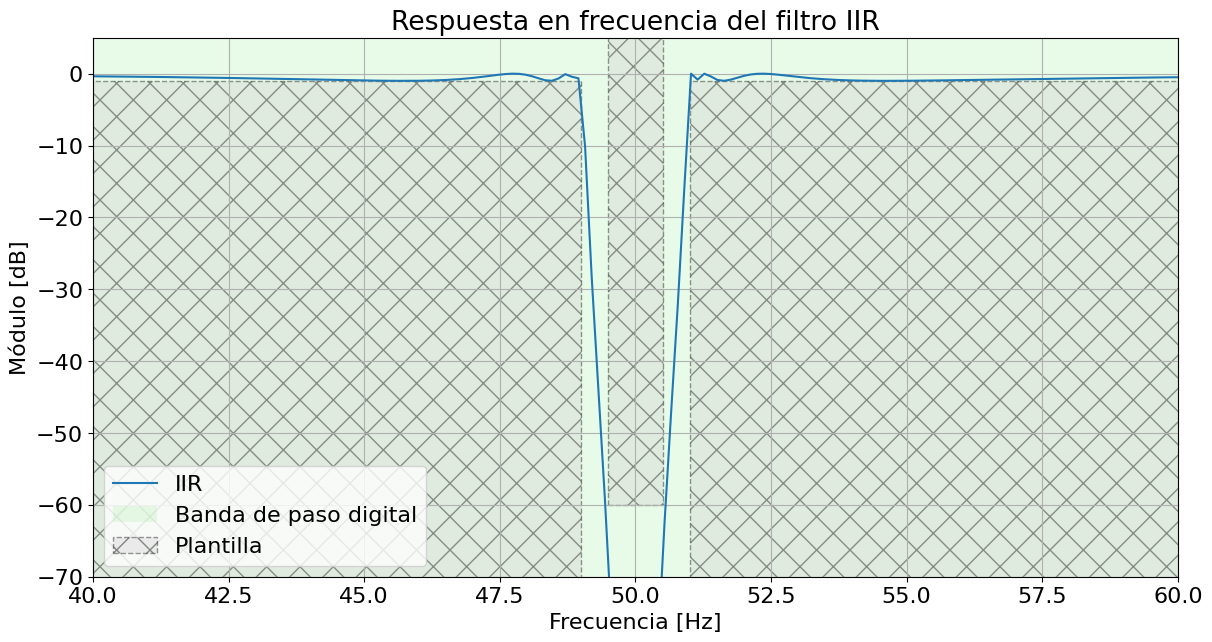

In [58]:
w_rad, h_iir = sig.freqz_sos(
    sos_iir,
    worN=4096,
    fs=fs
)

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    w_rad,
    20 * np.log10(np.abs(h_iir) + 1e-12),
    label='IIR'
)

plot_plantilla(
    filter_type='bandstop',
    fpass=(wp1, wp2),
    fstop=(ws1, ws2),
    ripple=ripple,
    attenuation=atenuacion,
    fs=fs
)

plt.title('Respuesta en frecuencia del filtro IIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.xlim(40, 60)
plt.ylim(-70, 5)
plt.grid()
plt.legend()
plt.show()

Nuevamente la respuesta obtenida muestra una fuerte atenuación alrededor de la frecuencia de $50\,Hz$, solo que en este caso mucho mayor que en el FIR, manteniendo los $0\ dB$ fuera de esta banda de rechazo.

### Comparación con la plantilla

Finalmente, se compararon las respuestas obtenidas mediante simulación con la plantilla de diseño definida previamente.

El objetivo es verificar que ambos filtros presenten el comportamiento esperado: una ganancia cercana a la unidad en las bandas pasantes y una fuerte atenuación alrededor de la frecuencia de notch de $50\,Hz$.

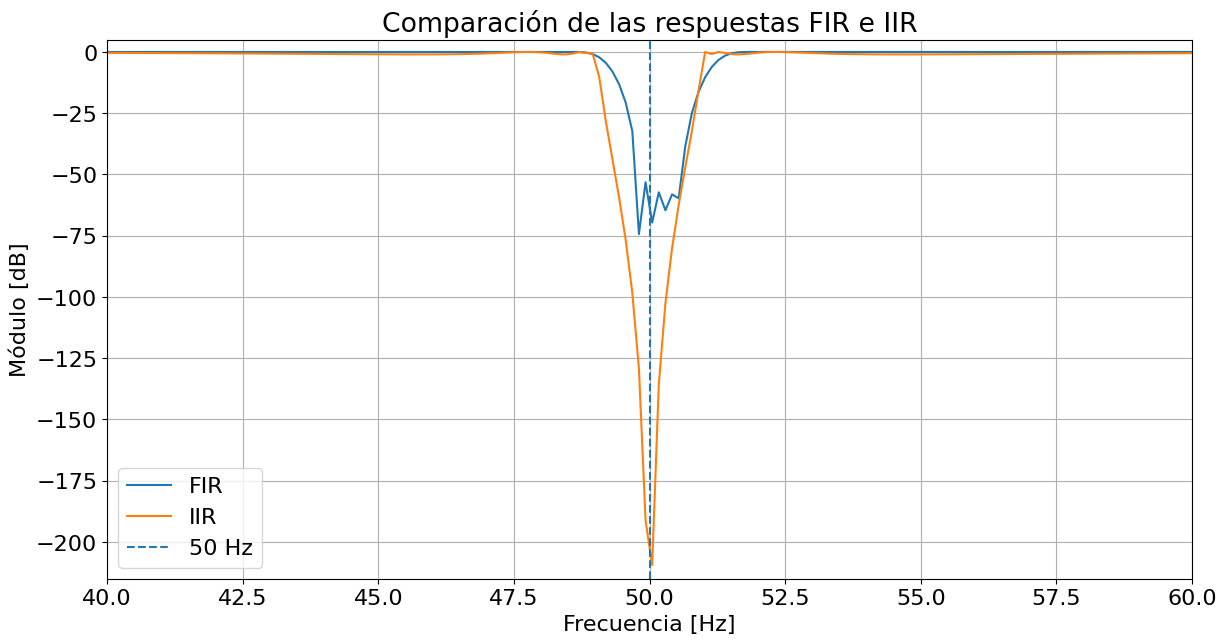

In [59]:
plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    w,
    20 * np.log10(np.abs(hh_win) + 1e-12),
    label='FIR'
)

plt.plot(
    w_rad,
    20 * np.log10(np.abs(h_iir) + 1e-12),
    label='IIR'
)

plt.axvline(
    50,
    linestyle='--',
    label='50 Hz'
)

plt.title('Comparación de las respuestas FIR e IIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.xlim(40, 60)
plt.ylim(-215, 5)
plt.grid()
plt.legend()
plt.show()

La figura permite comparar las respuestas en frecuencia de los filtros FIR e IIR, ambos diseñados para cumplir con las mismas especificaciones de rechazo alrededor de $50\,Hz$.

Se observa que ambos filtros presentan un rechazo centrado en $50\,Hz$ y una ganancia cercana a $0\,dB$ fuera de la zona de rechazo. El filtro IIR presenta una transición más pronunciada y una mayor profundidad de rechazo, mientras que el FIR presenta pequeñas variaciones dentro de la banda de rechazo.

### Fase

Además del módulo de la respuesta en frecuencia, se analizó la fase introducida por los filtros FIR e IIR. Esto permite observar el desfasaje que introduce cada filtro en función de la frecuencia.

#### Fase del filtro FIR

La fase del filtro FIR se representa utilizando una fase desenrollada para evitar los saltos de $2\pi$ propios de la representación de fase principal.


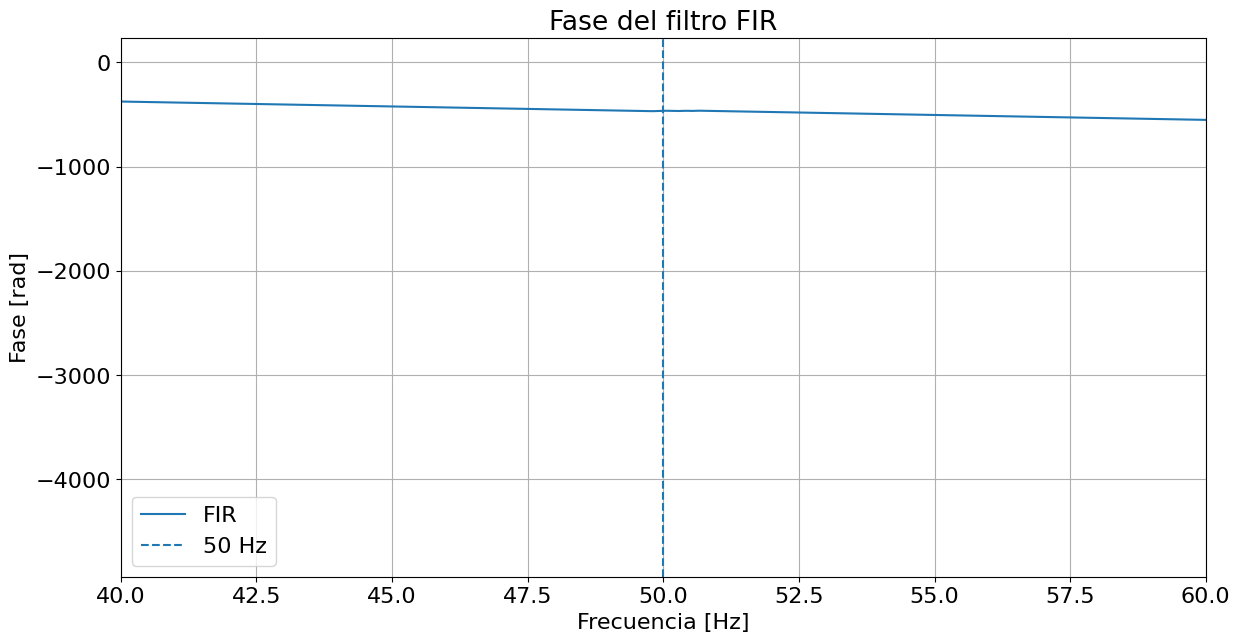

In [60]:

fase_fir = np.unwrap(np.angle(hh_win))

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    w,
    fase_fir,
    label='FIR'
)

plt.axvline(
    50,
    linestyle='--',
    label='50 Hz'
)

plt.title('Fase del filtro FIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [rad]')
plt.xlim(40, 60)
plt.grid()
plt.legend()
plt.show()

La fase del filtro FIR presenta una variación aproximadamente lineal con la frecuencia, característica de este tipo de filtro. Debido a la cantidad de coeficientes utilizados, la fase presenta valores absolutos elevados, asociados al retardo introducido por el filtro.

#### Fase del filtro IIR

Para el filtro IIR se analizó la fase en las proximidades de la frecuencia de notch, donde se produce una variación significativa asociada a la zona de rechazo.

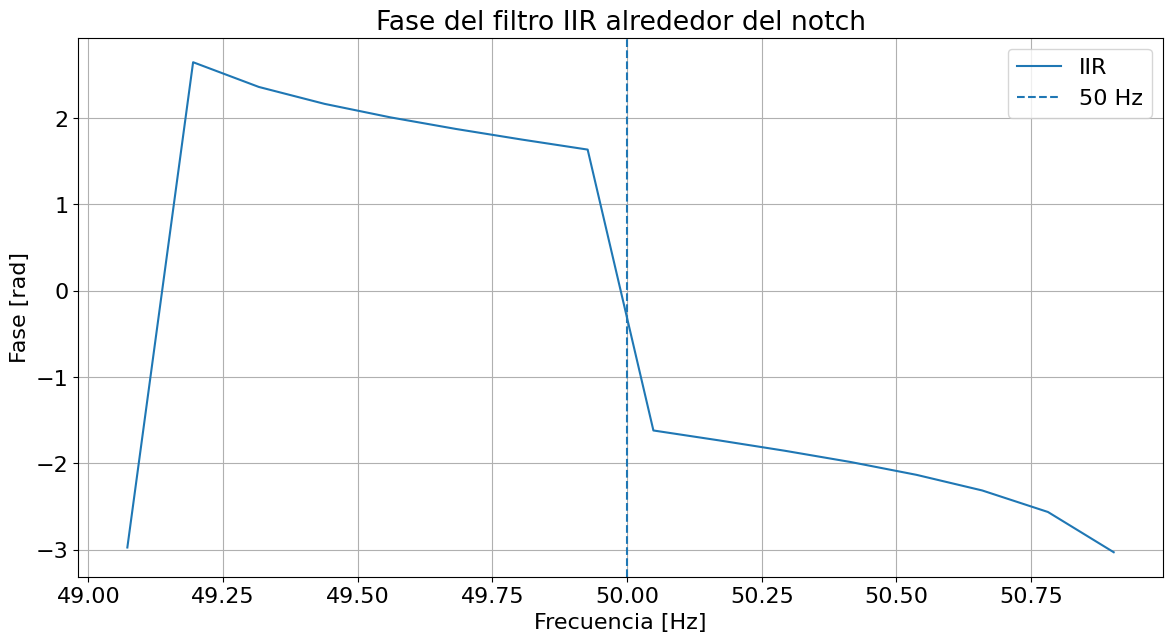

In [61]:
indices = (w_rad >= 49) & (w_rad <= 51)

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    w_rad[indices],
    np.angle(h_iir[indices]),
    label='IIR'
)

plt.axvline(
    50,
    linestyle='--',
    label='50 Hz'
)

plt.title('Fase del filtro IIR alrededor del notch')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [rad]')
plt.grid()
plt.legend()
plt.show()

Se observa una variación significativa de la fase alrededor de $50\,Hz$, coincidente con la zona de rechazo del filtro. Esta variación será posteriormente contrastada con las mediciones experimentales de desfasaje.

## Implementación en STM32

Una vez obtenidos los filtros digitales y verificado su comportamiento mediante simulación, se procedió a implementarlos en el microcontrolador STM32.

Los coeficientes calculados previamente se incorporaron al programa y se utilizaron para realizar el procesamiento de las muestras adquiridas mediante el ADC. La señal procesada fue posteriormente enviada al DAC para su reconstrucción.

La frecuencia de muestreo utilizada durante la implementación fue de $f_s=1000\,Hz$.

Se implementaron los dos filtros diseñados, FIR e IIR, con el objetivo de evaluar posteriormente su comportamiento mediante mediciones experimentales.

## Mediciones experimentales


### Talk-Through

Como primera prueba se utilizó el modo Talk-Through, con el objetivo de verificar el funcionamiento de la cadena completa antes de evaluar los filtros digitales.

Se aplicó una señal de entrada de $3\,V_{pp}$ y se midió la tensión de salida para diferentes frecuencias.

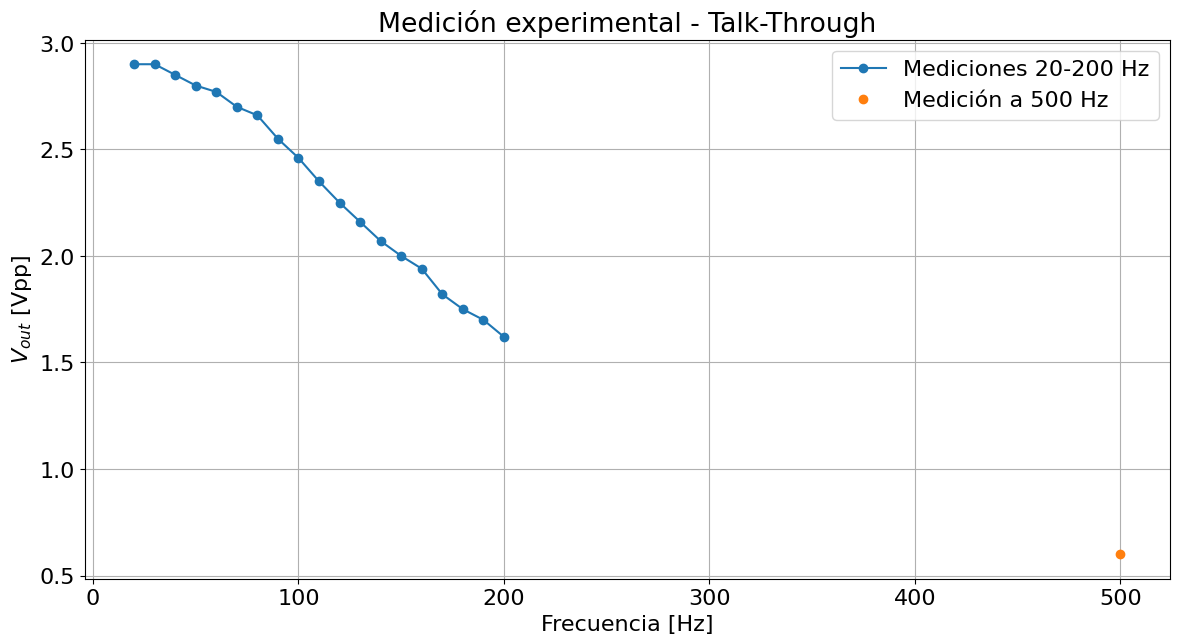

In [62]:
frecuencia_tt = np.array([
    20, 30, 40, 50, 60, 70, 80, 90, 100, 110,
    120, 130, 140, 150, 160, 170, 180, 190, 200, 500
])

vout_tt = np.array([
    2.90, 2.90, 2.85, 2.80, 2.77, 2.70, 2.66, 2.55, 2.46, 2.35,
    2.25, 2.16, 2.07, 2.00, 1.94, 1.82, 1.75, 1.70, 1.62, 0.60
])

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    frecuencia_tt[:-1],
    vout_tt[:-1],
    marker='o',
    label='Mediciones 20-200 Hz'
)

plt.plot(
    frecuencia_tt[-1],
    vout_tt[-1],
    marker='o',
    linestyle='None',
    label='Medición a 500 Hz'
)

plt.title('Medición experimental - Talk-Through')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('$V_{out}$ [Vpp]')
plt.grid()
plt.legend()
plt.show()

Para comprobar la atenuación introducida por los filtros analógicos se realizó una medición fuera del rango de frecuencias utilizado anteriormente, incorporando el punto correspondiente a $500\,Hz$. A partir del comportamiento observado en las frecuencias anteriores, se puede interpretar que la posición de este punto es consistente con la atenuación introducida por los filtros RC.

### Filtro FIR

Una vez verificado el funcionamiento de la cadena mediante el modo Talk-Through, se implementó el filtro FIR diseñado previamente.

Se realizó un barrido de frecuencia alrededor de la frecuencia de notch, utilizando pasos de $100\,mHz$ y manteniendo la señal de entrada en $3\,V_{pp}$.

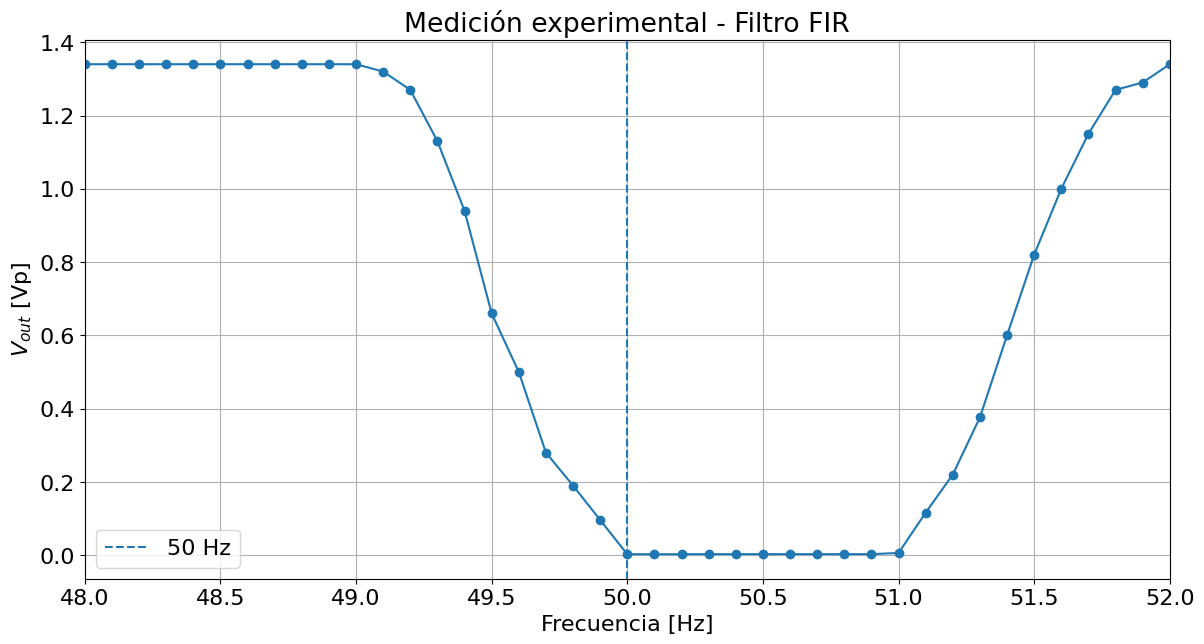

In [63]:
frecuencia_fir = np.array([
    48.0, 48.1, 48.2, 48.3, 48.4, 48.5, 48.6, 48.7, 48.8, 48.9,
    49.0, 49.1, 49.2, 49.3, 49.4, 49.5, 49.6, 49.7, 49.8, 49.9,
    50.0, 50.1, 50.2, 50.3, 50.4, 50.5, 50.6, 50.7, 50.8, 50.9,
    51.0, 51.1, 51.2, 51.3, 51.4, 51.5, 51.6, 51.7, 51.8, 51.9,
    52.0
])

vout_fir = np.array([
    1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34,
    1.34, 1.32, 1.27, 1.13, 0.94, 0.66, 0.50, 0.28, 0.19, 0.096,
    0.0026, 0.0026, 0.0026, 0.0028, 0.0028, 0.0028, 0.0028, 0.0028,
    0.0028, 0.0028, 0.0060, 0.116, 0.220, 0.376, 0.60, 0.82,
    1.00, 1.15, 1.27, 1.29, 1.34
])

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    frecuencia_fir,
    vout_fir,
    marker='o'
)

plt.axvline(
    50,
    linestyle='--',
    label='50 Hz'
)

plt.title('Medición experimental - Filtro FIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('$V_{out}$ [Vp]')
plt.xlim(48, 52)
plt.grid()
plt.legend()
plt.show()

### Filtro IIR

Finalmente se realizó la medición del filtro IIR. Al igual que en el caso del FIR, se efectuó un barrido de frecuencia alrededor de la frecuencia de notch, utilizando pasos de $100\,mHz$ y manteniendo la señal de entrada en $3\,V_{pp}$.

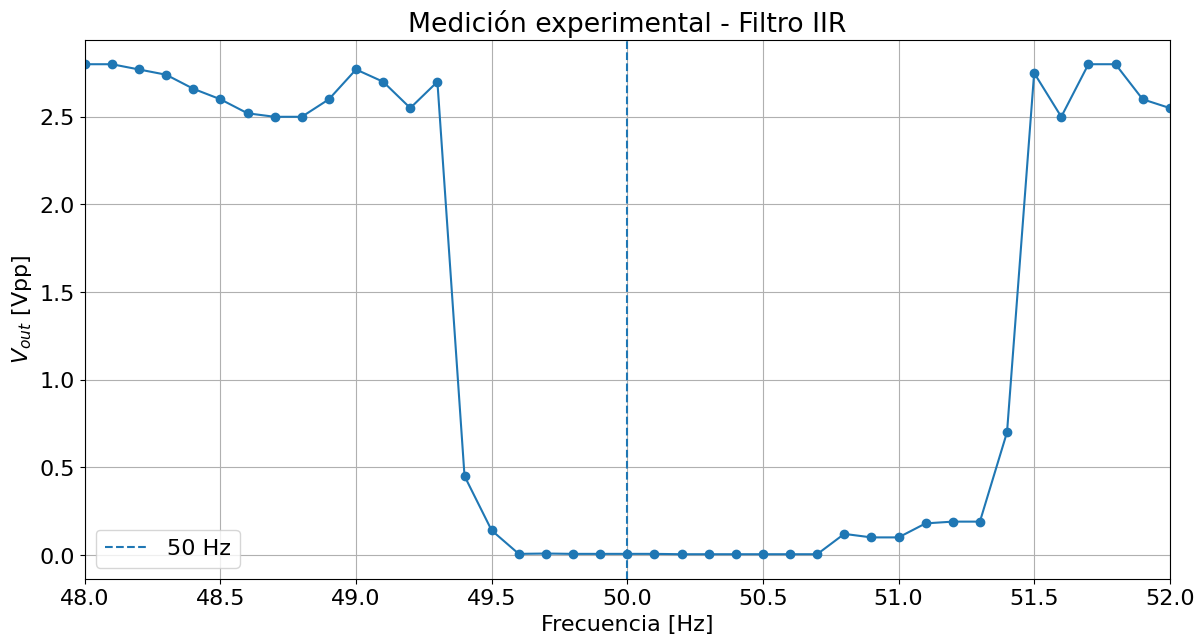

In [64]:
frecuencia_iir = np.array([
    48.0, 48.1, 48.2, 48.3, 48.4, 48.5, 48.6, 48.7, 48.8, 48.9,
    49.0, 49.1, 49.2, 49.3, 49.4, 49.5, 49.6, 49.7, 49.8, 49.9,
    50.0, 50.1, 50.2, 50.3, 50.4, 50.5, 50.6, 50.7, 50.8, 50.9,
    51.0, 51.1, 51.2, 51.3, 51.4, 51.5, 51.6, 51.7, 51.8, 51.9,
    52.0
])

vout_iir = np.array([
    2.80, 2.80, 2.77, 2.74, 2.66, 2.60, 2.52, 2.50, 2.50, 2.60,
    2.77, 2.70, 2.55, 2.70, 0.45, 0.14, 0.006, 0.008, 0.006, 0.006,
    0.006, 0.006, 0.004, 0.004, 0.004, 0.004, 0.004, 0.004, 0.12, 0.10,
    0.10, 0.18, 0.19, 0.19, 0.70, 2.75, 2.50, 2.80, 2.80, 2.60, 2.55
])

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    frecuencia_iir,
    vout_iir,
    marker='o'
)

plt.axvline(
    50,
    linestyle='--',
    label='50 Hz'
)

plt.title('Medición experimental - Filtro IIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('$V_{out}$ [Vpp]')
plt.xlim(48, 52)
plt.grid()
plt.legend()
plt.show()

### Comparación de las mediciones FIR e IIR

Para comparar directamente las respuestas experimentales de ambos filtros es necesario expresar las mediciones en la misma unidad.

En el caso del filtro FIR, la tensión de salida fue registrada como valor pico ($V_p$), mientras que para el filtro IIR se registró como tensión pico a pico ($V_{pp}$). Para realizar la comparación se convirtió la medición del FIR haciendo $V_{pp}=2V_p$.

De esta forma, ambas mediciones pueden representarse en una misma gráfica.

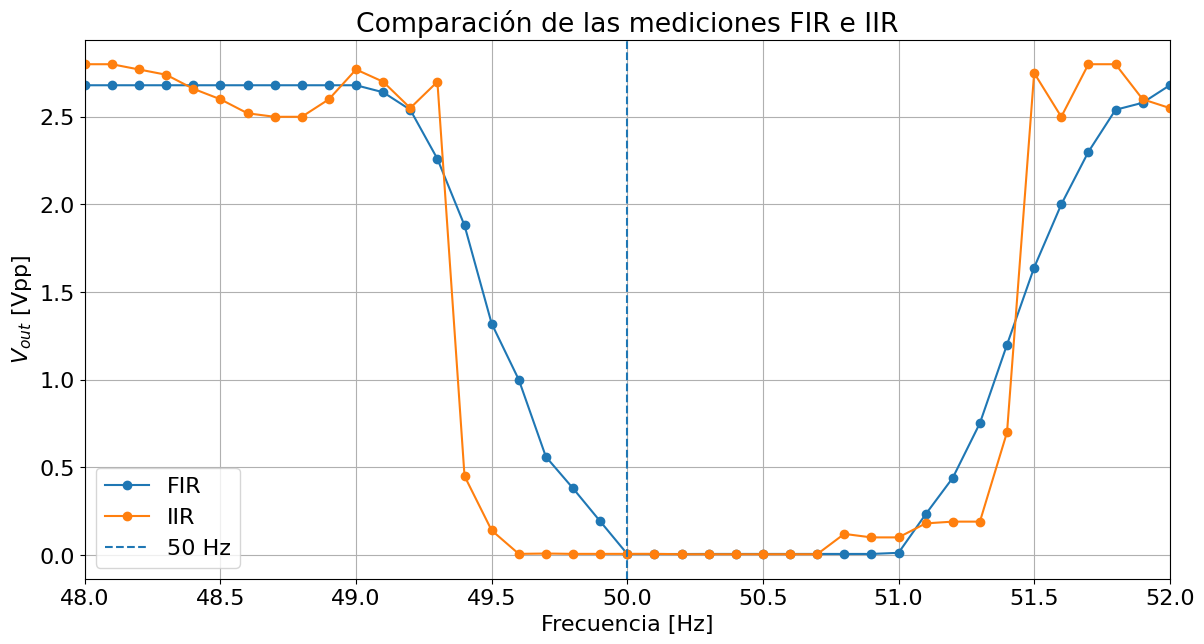

In [65]:
vout_fir_vpp = 2 * vout_fir

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    frecuencia_fir,
    vout_fir_vpp,
    marker='o',
    label='FIR'
)

plt.plot(
    frecuencia_iir,
    vout_iir,
    marker='o',
    label='IIR'
)

plt.axvline(
    50,
    linestyle='--',
    label='50 Hz'
)

plt.title('Comparación de las mediciones FIR e IIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('$V_{out}$ [Vpp]')
plt.xlim(48, 52)
plt.grid()
plt.legend()
plt.show()

### Medición del desfasaje

Además de la respuesta en amplitud, se midió el desfasaje introducido por los filtros FIR e IIR para distintas frecuencias.

El desfasaje se obtuvo a partir de la diferencia temporal entre la señal de entrada y la señal de salida. A partir de esta diferencia temporal puede calcularse la fase mediante:

$$\varphi = -2\pi f \Delta t$$

donde $f$ es la frecuencia de la señal y $\Delta t$ es el retardo temporal medido entre entrada y salida.

#### Desfasaje del filtro FIR

Para evaluar el desfasaje introducido por el filtro FIR se midió el retardo temporal entre la señal de entrada y la señal de salida para diferentes frecuencias.

A partir del retardo medido se calculó la fase mediante:

$$\varphi=-2\pi f\Delta t$$

donde $f$ es la frecuencia de la señal y $\Delta t$ es el retardo medido.

Las mediciones se realizaron entre $40\,Hz$ y $40.5\,Hz$.

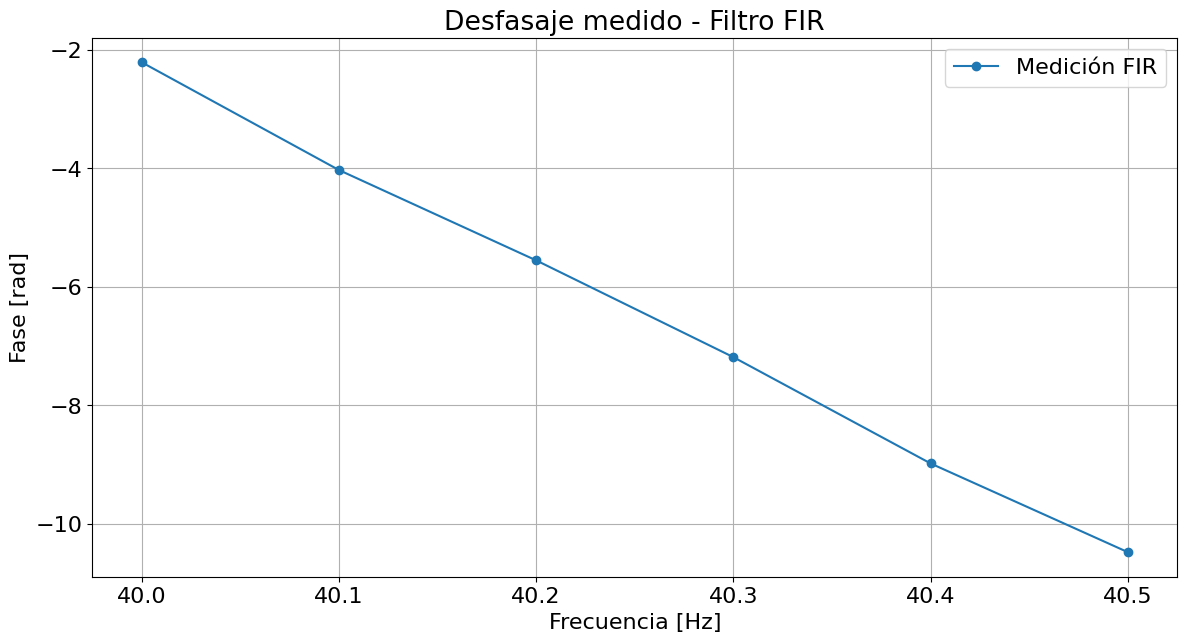

In [66]:
frecuencia_fir_fase = np.array([
    40.0, 40.1, 40.2, 40.3, 40.4, 40.5
])

retardo_fir = np.array([
    8.8, 16.0, 22.0, 28.4, 35.4, 41.2
])  # ms

# Conversión de ms a segundos
retardo_fir_s = retardo_fir / 1000

# Cálculo del desfasaje
fase_fir_medida = -2 * np.pi * frecuencia_fir_fase * retardo_fir_s

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    frecuencia_fir_fase,
    fase_fir_medida,
    marker='o',
    label='Medición FIR'
)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [rad]')
plt.title('Desfasaje medido - Filtro FIR')
plt.grid()
plt.legend()
plt.show()

#### Desfasaje del filtro IIR

Para el filtro IIR también se midió el retardo temporal entre la señal de entrada y la señal de salida para diferentes frecuencias.

A partir del retardo medido se calculó el desfasaje mediante:

$$\varphi=-2\pi f\Delta t$$

donde $f$ es la frecuencia de la señal y $\Delta t$ es el retardo temporal medido.

En este caso se realizaron mediciones a diferentes frecuencias para observar cómo varía el desfasaje del filtro.

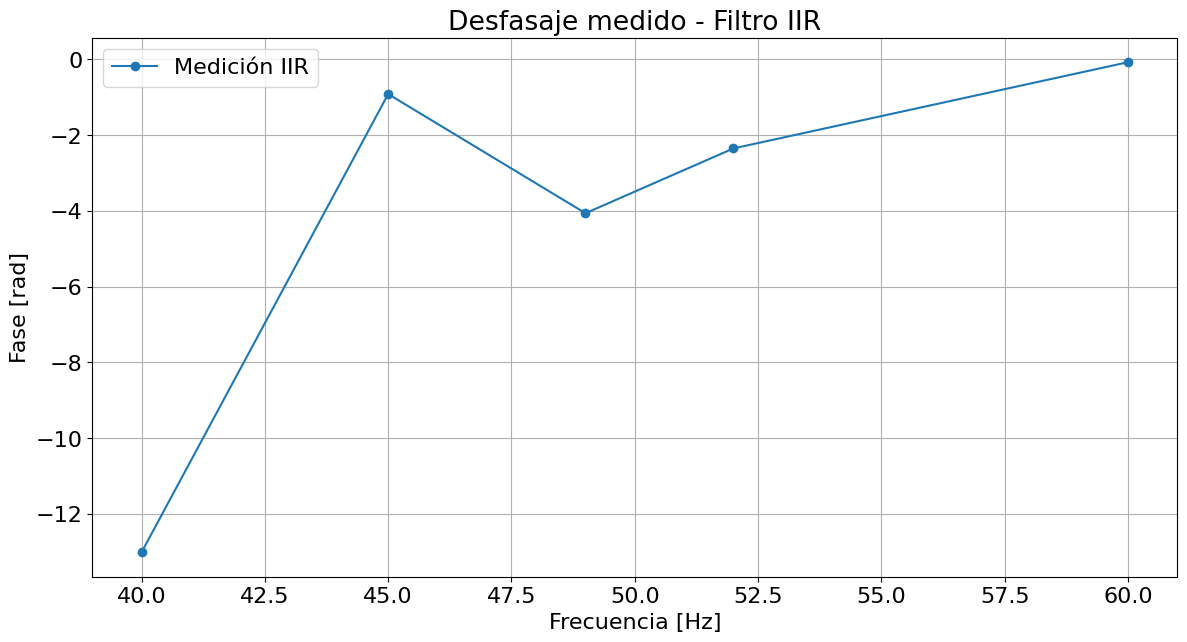

In [67]:
frecuencia_iir_fase = np.array([
    40, 45, 49, 52, 60
])

retardo_iir = np.array([
    51.8, 3.24, 13.2, 7.2, 0.2
])  # ms

# Conversión de ms a segundos
retardo_iir_s = retardo_iir / 1000

# Cálculo del desfasaje
fase_iir_medida = -2 * np.pi * frecuencia_iir_fase * retardo_iir_s

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    frecuencia_iir_fase,
    fase_iir_medida,
    marker='o',
    label='Medición IIR'
)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [rad]')
plt.title('Desfasaje medido - Filtro IIR')
plt.grid()
plt.legend()
plt.show()

Los resultados obtenidos para el FIR muestran una variación aproximadamente lineal del desfasaje con la frecuencia en el intervalo analizado.

En el caso del IIR, se observa una variación más marcada del desfasaje en las proximidades de la frecuencia de notch.  El punto medido a $40\,Hz$ presenta un valor de desfasaje considerablemente mayor que el resto de las mediciones, por lo que será tenido en cuenta posteriormente al analizar los resultados.

## Análisis de resultados

En esta sección se comparan los resultados obtenidos mediante simulación con las mediciones realizadas sobre el sistema implementado en el STM32.

Para facilitar la comparación, las mediciones de los filtros FIR e IIR se expresarán en $dB$ siguiendo la siguiente fórmula:
$$A_{dB}=20\log_{10}\left(\frac{V_{out}}{V_{in}}\right)$$

### Comparación del filtro FIR

Para comparar la respuesta simulada con la obtenida experimentalmente, se normalizaron las mediciones respecto de la tensión de entrada y se expresaron en decibeles.

En el caso del FIR, las mediciones fueron registradas como tensión pico ($V_p$), por lo que previamente se realizó la conversión a tensión pico a pico $V_{pp}=2V_p$.

De esta manera, la respuesta medida puede compararse con la respuesta obtenida mediante simulación.

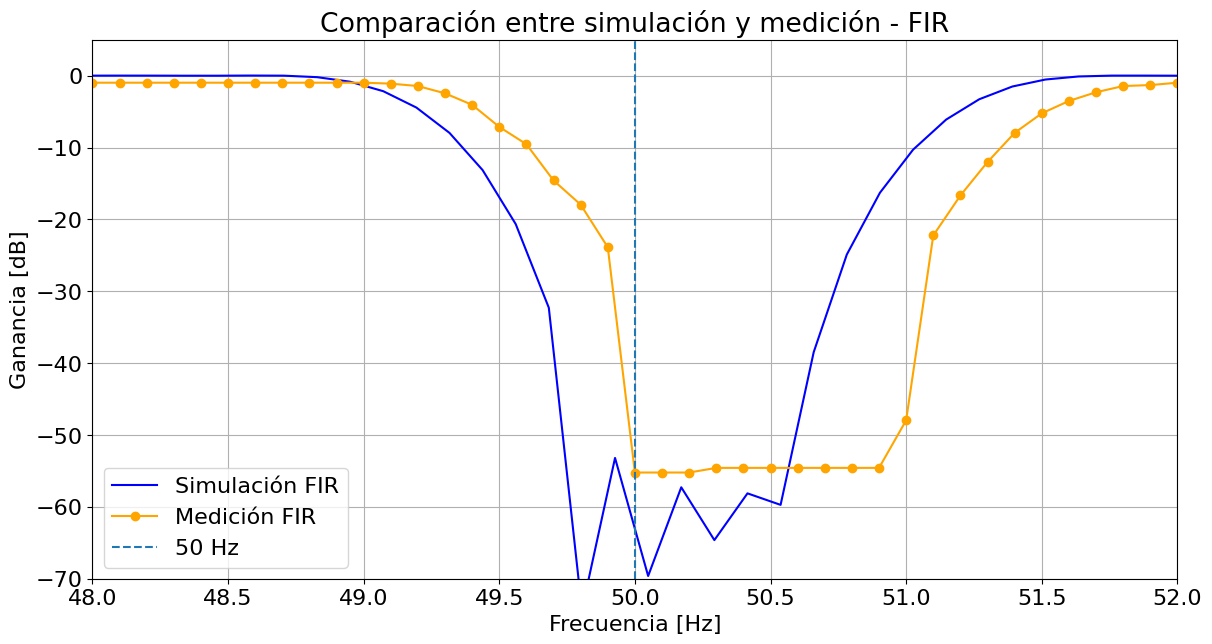

In [68]:
vout_fir_vpp = 2 * vout_fir

ganancia_fir_medida = 20 * np.log10(vout_fir_vpp / 3)
ganancia_fir_simulada = 20 * np.log10(np.abs(hh_win) + 1e-12)

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    w,
    ganancia_fir_simulada,
    color='blue',
    label='Simulación FIR'
)

plt.plot(
    frecuencia_fir,
    ganancia_fir_medida,
    color='orange',
    marker='o',
    label='Medición FIR'
)

plt.axvline(
    50,
    linestyle='--',
    label='50 Hz'
)

plt.title('Comparación entre simulación y medición - FIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Ganancia [dB]')
plt.xlim(48, 52)
plt.ylim(-70, 5)
plt.grid()
plt.legend()
plt.show()

### Comparación del filtro IIR

Para el filtro IIR se realizó el mismo procedimiento utilizado para el FIR. La tensión de salida medida se normalizó respecto de la señal de entrada de $3\,V_{pp}$ y se expresó en decibeles.

De esta manera se puede comparar directamente la respuesta experimental con la respuesta obtenida mediante simulación.

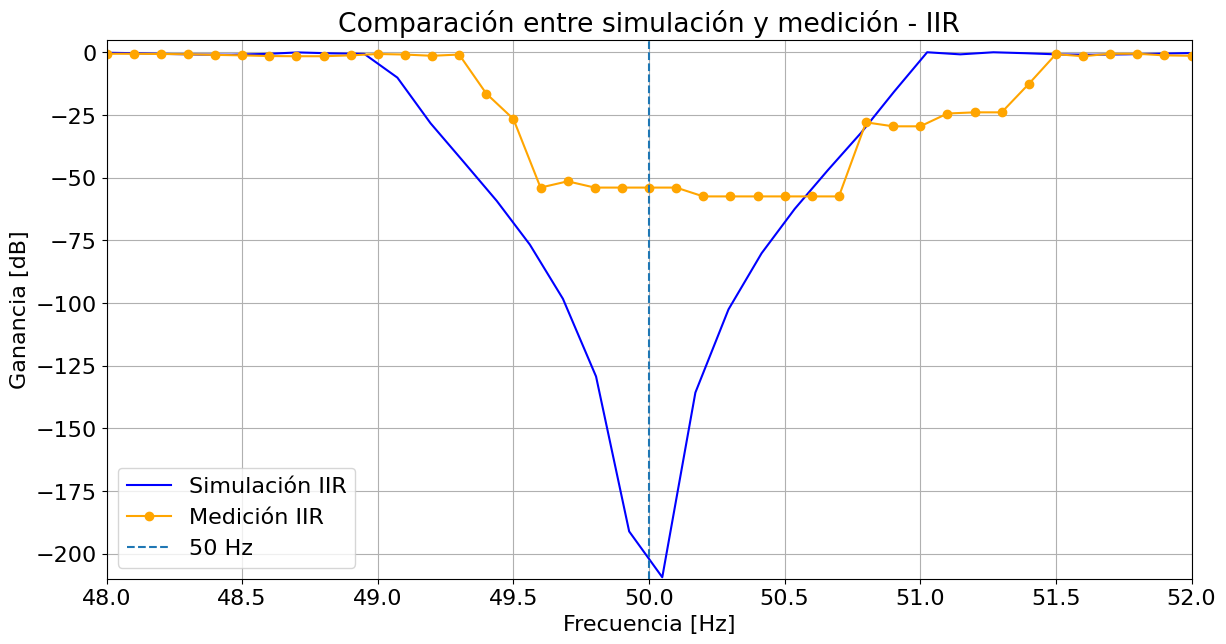

In [69]:
ganancia_iir_medida = 20 * np.log10(vout_iir / 3)
ganancia_iir_simulada = 20 * np.log10(np.abs(h_iir) + 1e-12)

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    w_rad,
    ganancia_iir_simulada,
    color='blue',
    label='Simulación IIR'
)

plt.plot(
    frecuencia_iir,
    ganancia_iir_medida,
    color='orange',
    marker='o',
    label='Medición IIR'
)

plt.axvline(
    50,
    linestyle='--',
    label='50 Hz'
)

plt.title('Comparación entre simulación y medición - IIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Ganancia [dB]')
plt.xlim(48, 52)
plt.ylim(-210, 5)
plt.grid()
plt.legend()
plt.show()

### Comparación del desfasaje

Finalmente se comparó el desfasaje obtenido experimentalmente con el obtenido mediante simulación.

La fase se obtiene a partir de la respuesta en frecuencia de cada filtro. Para la medición experimental se utilizó el retardo temporal medido entre la señal de entrada y la señal de salida, mediante:

$$\varphi=-2\pi f\Delta t$$

Debido a que la fase puede diferir en múltiplos de $2\pi$, para realizar la comparación se considera la evolución de la fase con la frecuencia, además de su valor absoluto.

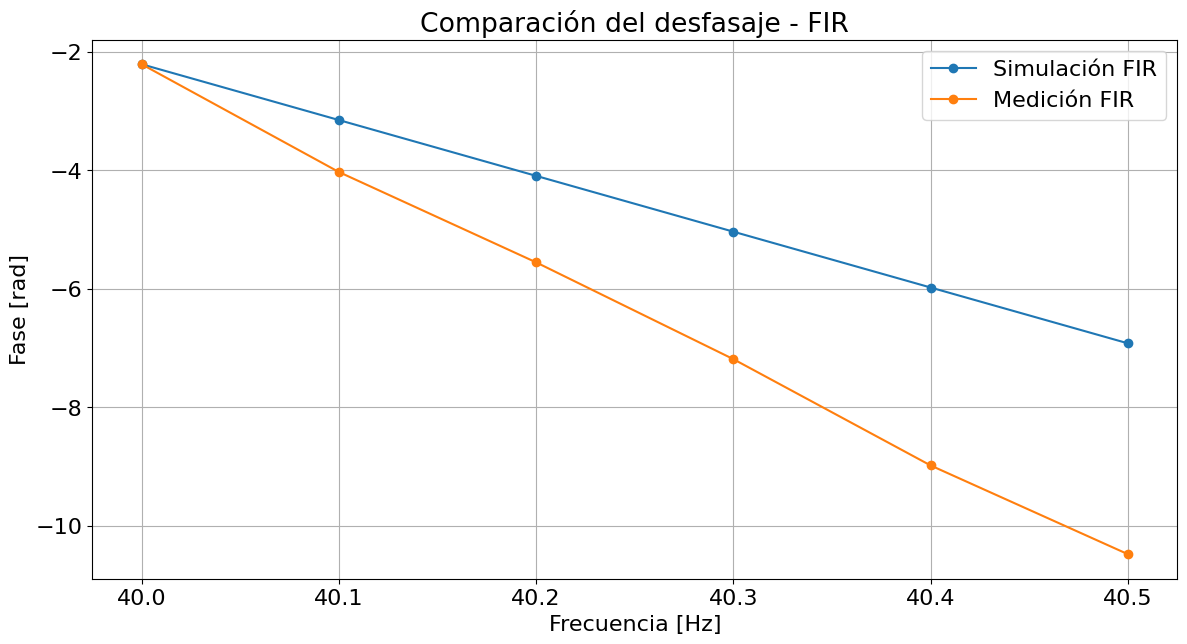

In [70]:
fase_fir_sim = np.unwrap(np.angle(hh_win))

frecuencia_fir_sim = w

fase_fir_sim_medida = np.interp(
    frecuencia_fir_fase,
    frecuencia_fir_sim,
    fase_fir_sim
)

# Se ajusta la fase simulada para que arranque desde el mismo lugar
offset_fir = fase_fir_medida[0] - fase_fir_sim_medida[0]
fase_fir_sim_ajustada = fase_fir_sim_medida + offset_fir

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    frecuencia_fir_fase,
    fase_fir_sim_ajustada,
    marker='o',
    label='Simulación FIR'
)

plt.plot(
    frecuencia_fir_fase,
    fase_fir_medida,
    marker='o',
    label='Medición FIR'
)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [rad]')
plt.title('Comparación del desfasaje - FIR')
plt.grid()
plt.legend()
plt.show()

En la comparación del desfasaje se observa que tanto la simulación como la medición presentan una variación aproximadamente lineal con la frecuencia, característica del comportamiento de fase lineal del filtro FIR.

Sin embargo, la pendiente obtenida experimentalmente es mayor que la correspondiente a la simulación. Esto indica que el retardo observado experimentalmente es superior al obtenido en la simulación para el intervalo analizado. Esta diferencia puede estar asociada a retardos adicionales introducidos por el sistema, además de las condiciones propias de la medición.

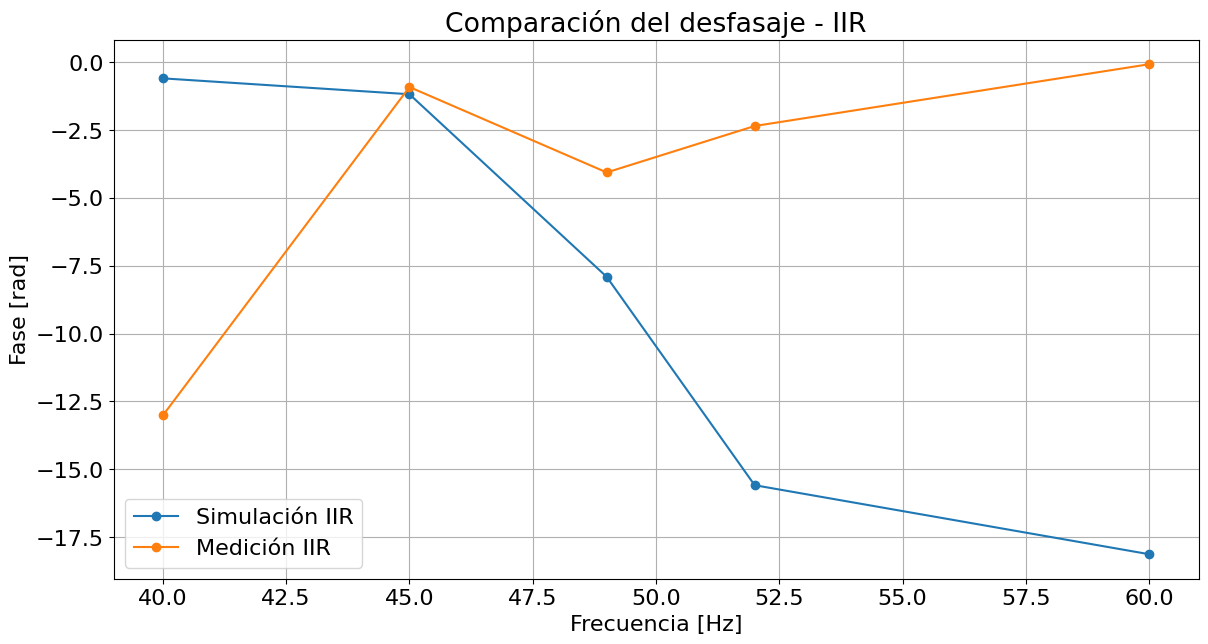

In [71]:
fase_iir_sim = np.unwrap(np.angle(h_iir))

frecuencia_iir_sim = w_rad

fase_iir_sim_medida = np.interp(
    frecuencia_iir_fase,
    frecuencia_iir_sim,
    fase_iir_sim
)

plt.figure(figsize=(fig_sz_x, fig_sz_y))

plt.plot(
    frecuencia_iir_fase,
    fase_iir_sim_medida,
    marker='o',
    label='Simulación IIR'
)

plt.plot(
    frecuencia_iir_fase,
    fase_iir_medida,
    marker='o',
    label='Medición IIR'
)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [rad]')
plt.title('Comparación del desfasaje - IIR')
plt.grid()
plt.legend()
plt.show()

En la comparación del desfasaje se observa que la respuesta simulada presenta una variación de fase más pronunciada en las proximidades de la frecuencia de rechazo de $50\,Hz$.

La medición experimental presenta una tendencia similar, aunque existen diferencias apreciables entre ambas respuestas. En particular, el valor medido a $40\,Hz$ presenta un desfasaje considerablemente mayor que el obtenido mediante simulación.

Las diferencias observadas pueden atribuirse a las condiciones de implementación y medición del sistema real, por lo que se podríamos decir que en este caso la medición no fue buena.

## Conclusiones

A partir de las mediciones realizadas se pudo verificar el funcionamiento de la cadena completa de adquisición y procesamiento digital mediante el modo Talk-Through, observándose el efecto de los filtros analógicos RC presentes en las etapas de entrada y salida.

La implementación de los filtros FIR e IIR permitió comprobar experimentalmente el funcionamiento de ambos filtros alrededor de la frecuencia de rechazo de $50\,Hz$. En ambos casos se obtuvo una atenuación significativa de la señal en las proximidades de dicha frecuencia, cumpliendo cualitativamente con el objetivo principal del diseño.

Al comparar las mediciones con las respuestas obtenidas mediante simulación se observaron diferencias tanto en la profundidad como en el ancho de la zona de rechazo. Esto es esperable ya que el simulado es un caso ideal, mientras que las mediciones fueron realizadas considerando todas las etapas reales, incluyendo los filtros analógicos, el ADC, el DAC y los efectos propios de la implementación experimental.

El FIR presentó una respuesta experimental que conserva las principales características observadas en la simulación. En el caso del IIR se observó una mayor discrepancia entre ambas respuestas, particularmente en el comportamiento de fase. A pesar de estas diferencias, las mediciones permitieron observar experimentalmente el comportamiento de ambos tipos de filtros.

El trabajo permitió ver la diferencia entre lo medido experimentalmente y lo simulado de las implementaciones FIR e IIR y ver como las condiciones reales afectan a este comportamiento ideal esperado.